In [25]:
import pandas as pd
import pickle
from falling_trees.frl_rashomon_set_alg import Node, TrieNode, Trie, Leaf, count_leaves, tree_obj, print_tree

In [2]:
R_falling = pickle.load(open("/home/users/zwb3/research/falling-models/Rashomon_set_compas_lambda_0.005_depth_5_eps_0.01_falling_constraint_True.pkl", "rb"))

In [41]:
def number_of_terms(node: Node, current_path=[]) -> int:
    # compute the total number of terms in a tree
    # this is the sum of the paths from root to each leaf
    if isinstance(node, Leaf):
        if node.pred_prob >= 0.5:
            return len(current_path)  # +1 for the leaf node
        else:
            return 0
    total_terms = 0
    left = node.left
    right = node.right
    
    for child in [left, right]:
        if child is not None:
            antecedent = current_path + [node.feature]
            total_terms += number_of_terms(child, antecedent)
    
    return total_terms

print_tree(R_falling[6][0])
number_of_terms(R_falling[6][0])

Node(feature=3)
  Node(feature=6)
    Node(feature=5)
      Leaf(pred_prob=0.366, objective=0.045)
      Leaf(pred_prob=0.577, objective=0.009)
    Leaf(pred_prob=0.636, objective=0.081)
  Node(feature=8)
    Leaf(pred_prob=0.635, objective=0.097)
    Leaf(pred_prob=0.295, objective=0.129)


7

In [43]:
terms = [number_of_terms(tree[0]) for tree in R_falling]
accuracy = [1-tree_obj(tree[0]) for tree in R_falling]

In [17]:
R_falling[0]

(Node(feature=3, left=Node(feature=6, left=Leaf(pred_prob=np.float64(0.3844282238442822), objective=np.float64(0.050750687708122195)), right=Leaf(pred_prob=np.float64(0.6355463347164592), objective=np.float64(0.08129940639930505)), objective=np.float64(0.13205009410742724)), right=Node(feature=8, left=Leaf(pred_prob=np.float64(0.6352670878805284), objective=np.float64(0.09693571738815694)), right=Leaf(pred_prob=np.float64(0.2950310559006211), objective=np.float64(0.12878746199507746)), objective=np.float64(0.22572317938323438)), objective=np.float64(0.3577732734906616)),
 np.float64(0.6355463347164592),
 3,
 np.float64(0.3577732734906616))

In [4]:
from frame.rashomon_sets import FRLRashomonSet
df = pd.read_csv("/home/users/zwb3/research/falling-models/compas_binarized.csv")
X = df.iloc[:, :-1]
y = df.iloc[:, -1]

In [5]:
df.describe()

,sex:Female<=0.5,age:<21<=0.5,age:<23<=0.5,age:<26<=0.5,age:<46<=0.5,juvenile-crimes:=0<=0.5,priors:=0<=0.5,priors:=1<=0.5,priors:>3<=0.5,recidivate-within-two-years:1
count,6907.000000,6907.000000,6907.000000,6907.000000,6907.000000,6907.000000,6907.000000,6907.000000,6907.000000,6907.000000
mean,0.807731,0.898798,0.804836,0.671637,0.176632,0.136528,0.695816,0.811496,0.685247,0.462719
std,0.394112,0.301617,0.396356,0.469651,0.381385,0.343373,0.460094,0.391143,0.464451,0.498644
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
50%,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
75%,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [6]:
rset = FRLRashomonSet()
rset.fit(X.astype(bool), y, curiosity_func="reward", verbose=True)

2025-12-31 15:21:02,233 - INFO - Starting fit method
2025-12-31 15:21:02,239 - INFO - Including complement of features
2025-12-31 15:21:02,243 - INFO - Features: Index(['sex:Female<=0.5', 'age:<21<=0.5', 'age:<23<=0.5', 'age:<26<=0.5',
       'age:<46<=0.5', 'juvenile-crimes:=0<=0.5', 'priors:=0<=0.5',
       'priors:=1<=0.5', 'priors:>3<=0.5', '~sex:Female<=0.5', '~age:<21<=0.5',
       '~age:<23<=0.5', '~age:<26<=0.5', '~age:<46<=0.5',
       '~juvenile-crimes:=0<=0.5', '~priors:=0<=0.5', '~priors:=1<=0.5',
       '~priors:>3<=0.5'],
      dtype='object')
2025-12-31 15:21:02,244 - INFO - Mining antecedents
2025-12-31 15:21:05,110 - INFO - Number of mined antecedents (min_support=0.03, max_len=2): 146
2025-12-31 15:21:05,111 - INFO - Building antecedent map
2025-12-31 15:21:05,260 - INFO - Optimizing falling rule list
Optimizing rule list: 100%|██████████| 3000/3000 [00:03<00:00, 859.35it/s]
2025-12-31 15:21:08,757 - INFO - Falling rule list optimization complete
Optimizing rule list:

In [12]:
from sklearn.metrics import accuracy_score

def frl_sparsity(frl):
    total_terms = 0
    for antecedent, _ in frl.rule_list:
        total_terms += len(antecedent)
    return total_terms

def frl_leaves(frl):
    return 2*len(frl.rule_list)-1

def frl_accuracy(frl, X, y):
    y_pred = frl.predict(X)
    return accuracy_score(y, y_pred)

In [8]:
frl_sparsity(rset.rset[0])

7

In [9]:
X_ = X.copy()
for col in X.columns:
    X_['~' + col] = ~X[col].astype(bool)
X_ = X_.astype(bool)

In [10]:
frl_accuracy(rset.rset[0], X_, y)

0.6578833067902128

In [13]:
frl_leaves(rset.rset[0])

9

In [24]:
sparsity_frl = [frl_sparsity(model) for model in rset.rset]
accuracy_frl = [frl_accuracy(model, X_, y) for model in rset.rset]

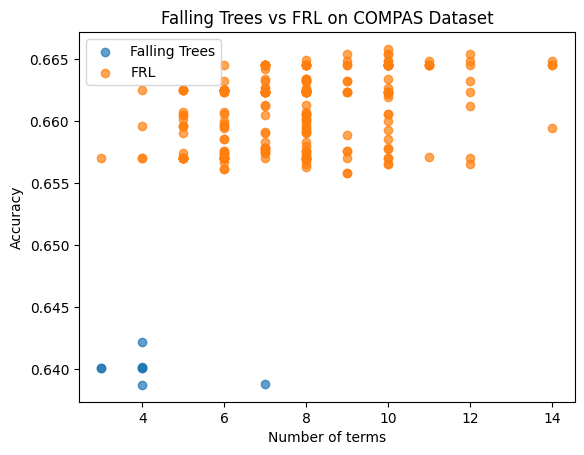

In [44]:
import matplotlib.pyplot as plt
plt.scatter(terms, accuracy, label='Falling Trees', alpha=0.7)
plt.scatter(sparsity_frl, accuracy_frl, label='FRL', alpha=0.7)
plt.xlabel('Number of terms')
plt.ylabel('Accuracy')
plt.title('Falling Trees vs FRL on COMPAS Dataset')
plt.legend()
plt.show()